In [38]:
#Bolli Yaswanth Melki , 92400133114 , 5EK2B.
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from google.colab import drive


In [40]:
dataset = pd.read_csv('/content/diabetes.csv')
print(dataset)
print(dataset.shape)

     Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0              6      148             72             35        0  33.6   
1              1       85             66             29        0  26.6   
2              8      183             64              0        0  23.3   
3              1       89             66             23       94  28.1   
4              0      137             40             35      168  43.1   
..           ...      ...            ...            ...      ...   ...   
103            1       81             72             18       40  26.6   
104            2       85             65              0        0  39.6   
105            1      126             56             29      152  28.7   
106            1       96            122              0        0  22.4   
107            4      144             58             28      140  29.5   

     DiabetesPedigreeFunction  Age  Outcome  
0                       0.627   50        1  
1                  

In [41]:
print(dataset.describe())
pregnancies_value = dataset.iloc[0:dataset.shape[0], 0:1]
glucose_value = dataset.iloc[0:dataset.shape[0], 1:2]

       Pregnancies     Glucose  BloodPressure  SkinThickness     Insulin  \
count    108.00000  108.000000     108.000000     108.000000  108.000000   
mean       4.37037  118.194444      68.592593      19.120370   71.916667   
std        3.56932   33.399160      22.038215      16.289276  123.098860   
min        0.00000    0.000000       0.000000       0.000000    0.000000   
25%        1.00000   98.500000      64.000000       0.000000    0.000000   
50%        4.00000  113.500000      72.000000      20.000000    0.000000   
75%        7.00000  139.500000      80.000000      32.000000  110.000000   
max       15.00000  197.000000     122.000000      60.000000  846.000000   

              BMI  DiabetesPedigreeFunction         Age     Outcome  
count  108.000000                108.000000  108.000000  108.000000  
mean    30.870370                  0.472815   33.833333    0.351852  
std      9.412373                  0.371791   11.086322    0.479774  
min      0.000000                  

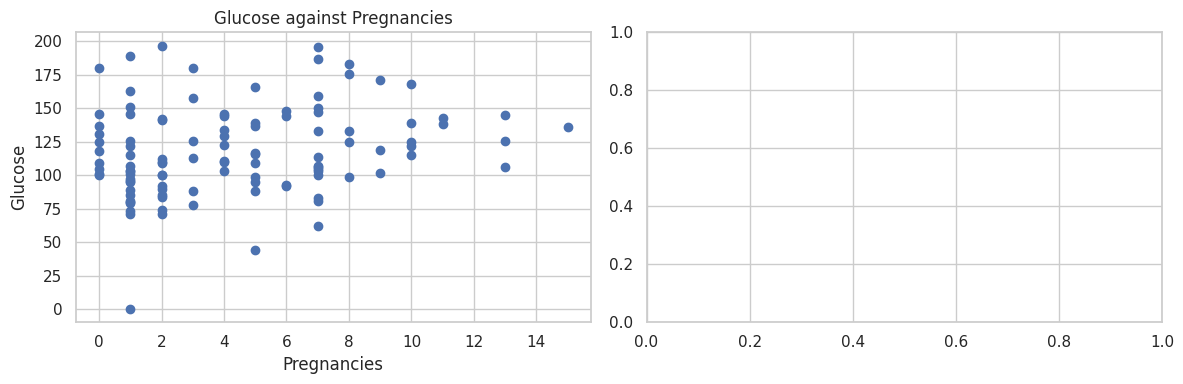

In [42]:
fig, axes = plt.subplots(figsize=(12,4), nrows=1, ncols=2)
axes[0].scatter(pregnancies_value, glucose_value, color='b')
axes[0].set_xlabel('Pregnancies')
axes[0].set_ylabel('Glucose')
axes[0].set_title('Glucose against Pregnancies')
plt.tight_layout()

In [43]:
def featureNormalization(X):
    mean = np.mean(X, axis=0)
    std = np.std(X, axis=0)
    X_norm = (X - mean) / std
    return X_norm, mean, std

data_norm = dataset.values
m2 = len(data_norm[:, -1])
X2 = data_norm[:, 0:1].reshape(m2, 1)
X2, mean_X2, std_X2 = featureNormalization(X2)
X2 = np.append(np.ones((m2, 1)), X2, axis=1)
y2 = data_norm[:, 1].reshape(m2, 1)
theta2 = np.zeros((2, 1))
X2

array([[ 1.        ,  0.45869432],
       [ 1.        , -0.94866325],
       [ 1.        ,  1.02163735],
       [ 1.        , -0.94866325],
       [ 1.        , -1.23013476],
       [ 1.        ,  0.17722281],
       [ 1.        , -0.38572022],
       [ 1.        ,  1.58458037],
       [ 1.        , -0.66719174],
       [ 1.        ,  1.02163735],
       [ 1.        , -0.10424871],
       [ 1.        ,  1.58458037],
       [ 1.        ,  1.58458037],
       [ 1.        , -0.94866325],
       [ 1.        ,  0.17722281],
       [ 1.        ,  0.74016583],
       [ 1.        , -1.23013476],
       [ 1.        ,  0.74016583],
       [ 1.        , -0.94866325],
       [ 1.        , -0.94866325],
       [ 1.        , -0.38572022],
       [ 1.        ,  1.02163735],
       [ 1.        ,  0.74016583],
       [ 1.        ,  1.30310886],
       [ 1.        ,  1.86605189],
       [ 1.        ,  1.58458037],
       [ 1.        ,  0.74016583],
       [ 1.        , -0.94866325],
       [ 1.        ,

In [44]:
def cost_function(theta_array, x1_value, y_value, m):
    total_error = 0
    for i in range(m):
        total_error += ((theta_array[0] + theta_array[1] * x1_value[i]) - y_value[i]) ** 2
    return total_error / (2 * m)

alpha = 0.01
iters = 500

In [45]:
def hypothesis(theta_array, x1):
    return theta_array[0] + theta_array[1] * x1

In [46]:
def improvise_thetas(theta_array, X1, Y, alpha, m):
    summation_0 = 0
    summation_1 = 0
    for i in range(m):
        summation_0 += (theta_array[0] + theta_array[1] * X1[i]) - Y[i]
        summation_1 += X1[i] * ((theta_array[0] + theta_array[1] * X1[i]) - Y[i])
    new_theta_0 = theta_array[0] - alpha * (summation_0) / m
    new_theta_1 = theta_array[1] - alpha * (summation_1) / m
    return [new_theta_0[0], new_theta_1[0]]

In [47]:
def training(x1_train, y_train, alpha, iters):
    m = x1_train.size
    theta_0 = 0
    theta_1 = 0
    theta_array = [theta_0, theta_1]
    cost_function_values = []
    for i in range(iters):
        theta_array = improvise_thetas(theta_array, x1_train, y_train, alpha, m)
        cost_function_values.append(cost_function(theta_array, x1_train, y_train, m))
    return theta_array, cost_function_values

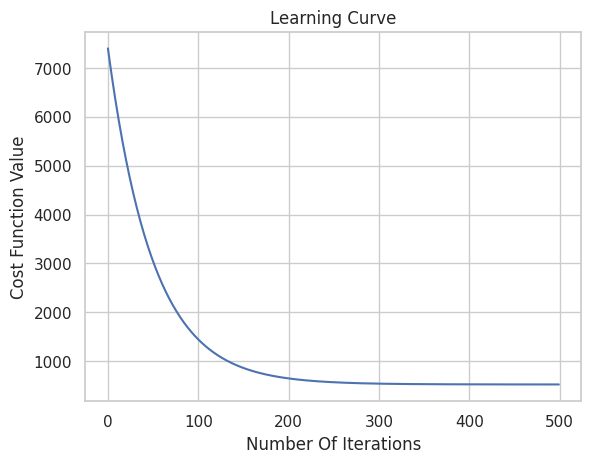

In [48]:
theta_array, cost_function_values = training(X2[:, 1:2], y2, alpha, iters)
x = np.arange(0, len(cost_function_values), step=1)
plt.plot(x, cost_function_values, '-b')
plt.title('Learning Curve')
plt.xlabel('Number Of Iterations')
plt.ylabel('Cost Function Value')
plt.show()

In [49]:
print('the final value of theta_0 is ', theta_array[0])
print('the final value of theta_1 is ', theta_array[1])
predict = hypothesis(theta_array, 2)
print('predicted value: ', predict)

the final value of theta_0 is  117.41784985151459
the final value of theta_1 is  7.6332233212249
predicted value:  132.68429649396438
